# 🧠 Laboratorio: Cómo funciona un LLM por dentro
## Del texto a la predicción, paso a paso

**CENESTUR — Escuela de Informática** · Inteligencia Artificial / Redes Neuronales

---

> **Idea central del laboratorio**
> Un LLM (*Large Language Model*) es una **red neuronal entrenada con descenso por gradiente**.
> La **escala** (miles de millones de parámetros, terabytes de texto) y la **arquitectura**
> (Transformer con *atención*) producen **capacidades emergentes** que no aparecen en redes pequeñas.
> Pero internamente **no es magia**: es **álgebra lineal masivamente paralela**.

En este laboratorio vas a **construir tú mismo** cada pieza de un LLM y a **entrenar un modelo de
lenguaje real en miniatura** que aprende a escribir. Al terminar vas a poder explicar, con código en
la mano, qué pasa exactamente entre que escribes un texto y el modelo predice la siguiente palabra.

### 🎯 Objetivos de aprendizaje
Al finalizar el estudiante será capaz de:
1. **Tokenizar** texto y explicar por qué una red solo opera con números.
2. Describir qué son los **embeddings** y los **embeddings posicionales**.
3. Implementar **self-attention** paso a paso e interpretar la **matriz de atención**.
4. Ensamblar un **bloque Transformer** completo (atención + MLP + residual + LayerNorm).
5. Convertir activaciones en una **distribución de probabilidad** y **muestrear** el siguiente token.
6. Entrenar un mini-LLM con **descenso por gradiente** y observar cómo **aprende**.
7. Relacionar **escala** con **capacidades emergentes**.

### 🧩 Cómo usar este cuaderno
- Ejecuta las celdas **en orden** (cada una depende de las anteriores).
- Lee las explicaciones, observa las **matrices** y **mapas de calor**, y resuelve los `# 🛠️ EJERCICIO`.
- Anota tus respuestas a las **preguntas de reflexión** del final: son parte de la entrega.

### ✅ Requisitos
`python 3.10+`, `numpy`, `matplotlib` y `torch` (CPU es suficiente). Para instalar PyTorch:
`pip install torch` · No se necesita GPU ni conexión a internet.

## 0 · Preparación del entorno
Importamos las librerías y fijamos las **semillas** para que los resultados sean **reproducibles**
(cada vez que ejecutes el cuaderno obtendrás lo mismo).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)          # reproducibilidad en NumPy

def softmax(x, axis=-1):
    """Convierte un vector de numeros reales en una distribucion de probabilidad
    (todos positivos y suman 1). Restamos el maximo por estabilidad numerica."""
    x = x - x.max(axis=axis, keepdims=True)
    e = np.exp(x)
    return e / e.sum(axis=axis, keepdims=True)

def heatmap(M, title, xt=None, yt=None, cmap='viridis', fmt=None):
    fig, ax = plt.subplots(figsize=(0.6*M.shape[1]+2, 0.6*M.shape[0]+1.5))
    im = ax.imshow(M, cmap=cmap, aspect='auto')
    ax.set_title(title)
    if xt is not None: ax.set_xticks(range(len(xt))); ax.set_xticklabels(xt)
    if yt is not None: ax.set_yticks(range(len(yt))); ax.set_yticklabels(yt)
    if fmt is not None:
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                ax.text(j, i, format(M[i,j], fmt), ha='center', va='center',
                        color='w', fontsize=8)
    fig.colorbar(im, ax=ax); plt.tight_layout(); plt.show()

print('Entorno listo ✔')

Entorno listo ✔


In [2]:
# Corpus de entrenamiento - Sistemas Embebidos
with open("corpus_sistemas_embebidos.txt", "r", encoding="utf-8") as f:
    texto = f.read()

# Vocabulario: todos los caracteres distintos, ordenados
chars = sorted(list(set(texto)))
V = len(chars)                       # tamaño del vocabulario
stoi = {c: i for i, c in enumerate(chars)}   # string -> int
itos = {i: c for i, c in enumerate(chars)}   # int -> string

encode = lambda s: [stoi[c] for c in s]      # texto  -> lista de tokens
decode = lambda t: ''.join(itos[i] for i in t)  # tokens -> texto

print(f'Tamaño del corpus : {len(texto)} caracteres')
print(f'Vocabulario (V)   : {V} tokens distintos')
print('Tokens:', ''.join(chars).replace(' ', '·'))
print()
demo = 'sistema embebido'
print(f'encode({demo!r}) = {encode(demo)}')
print(f'decode(...)       = {decode(encode(demo))!r}')

Tamaño del corpus : 69004 caracteres
Vocabulario (V)   : 76 tokens distintos
Tokens: 
·+,-./0123456789:;ABCDEFGHIJLMNOPQRSTUVWXZabcdefghijklmnopqrstuvwxyzµáéíñóú

encode('sistema embebido') = [61, 51, 61, 62, 47, 55, 43, 1, 47, 55, 44, 47, 44, 51, 46, 57]
decode(...)       = 'sistema embebido'


## 1 · Tokenización — de **texto** a **números**

Una red neuronal **no entiende letras**: solo sabe multiplicar y sumar números. El primer paso de
**todo** LLM es convertir el texto en una lista de enteros llamados **tokens**.

Para que sea totalmente transparente usaremos un tokenizador **a nivel de carácter**: cada carácter
distinto es un token. (Los LLM reales usan *subpalabras* con algoritmos como **BPE**, pero la idea
es idéntica: texto → enteros.)

**Observa:** `la atencion` se transformó en una lista de enteros. *Eso* es lo que realmente
"ve" el modelo. Reconstruirlo (`decode`) nos devuelve el texto.

> 🛠️ **EJERCICIO 1.** Codifica tu nombre con `encode(...)`. ¿Qué token corresponde al espacio
> (`' '`)? ¿Por qué un tokenizador por caracteres genera secuencias *más largas* que uno por
> subpalabras (BPE)?

In [3]:
# 🛠️ EJERCICIO 1 — escribe aqui tu prueba:
# print(encode('tu nombre'))


## 2 · Embeddings — de **números** a **vectores con significado**

Un token es solo un identificador (p. ej. el `7`). No tiene magnitud útil. La red asocia a cada token
un **vector de `d` números reales** llamado **embedding**. Estos vectores **se aprenden** durante el
entrenamiento, de modo que tokens "parecidos" terminan con vectores parecidos.

La tabla de embeddings es una matriz **E** de tamaño `[V, d]`: una fila por token.

Además, como el Transformer procesa todos los tokens **en paralelo**, no sabe *en qué orden* van.
Por eso sumamos un **embedding posicional**: un vector distinto para la posición 0, 1, 2, …

In [4]:
d = 16  # dimension del embedding (en GPT-3 es 12288; aqui lo hacemos pequeno para verlo)

# Tablas de embeddings inicializadas al azar (aun NO han aprendido nada)
E_tok = np.random.randn(V, d) * 0.1        # embedding de token   [V, d]
E_pos = np.random.randn(64, d) * 0.1       # embedding posicional [maxlen, d]

def embed(tokens):
    """Convierte una lista de tokens en una matriz [T, d]:
       embedding del token  +  embedding de su posicion."""
    tok = E_tok[tokens]                     # [T, d]
    pos = E_pos[np.arange(len(tokens))]     # [T, d]
    return tok + pos

seq = encode('la atencion')
X = embed(seq)
print(f'Secuencia de {len(seq)} tokens  ->  matriz X de forma {X.shape}  (T x d)')
print(f'\nVector (embedding) del primer token {seq[0]!r}={itos[seq[0]]!r}:')
print(np.round(X[0], 3))

Secuencia de 11 tokens  ->  matriz X de forma (11, 16)  (T x d)

Vector (embedding) del primer token 54='l':
[-0.129 -0.011 -0.055  0.248 -0.053  0.232  0.046 -0.038 -0.156 -0.086
  0.001  0.165  0.045  0.243 -0.057 -0.018]


Cada **fila** de `X` es un token convertido en un punto en un espacio de `d` dimensiones.
Veamos qué tan "parecidos" son entre sí algunos tokens midiendo la **similitud coseno**
(1 = misma dirección, 0 = perpendiculares). Como los embeddings aún son aleatorios, **no** habrá
estructura; tras entrenar, sí la habría.

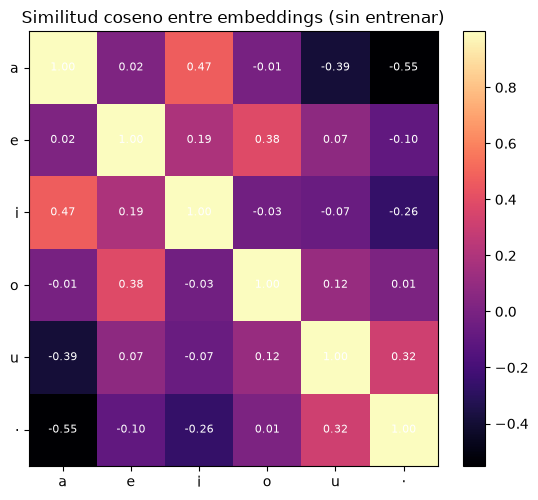

In [5]:
def cos_sim(A):
    n = A / (np.linalg.norm(A, axis=1, keepdims=True) + 1e-9)
    return n @ n.T

letras = list('aeiou ')                 # comparamos algunas vocales y el espacio
idx = [stoi[c] for c in letras]
S = cos_sim(E_tok[idx])
heatmap(S, 'Similitud coseno entre embeddings (sin entrenar)',
        xt=[c.replace(' ','·') for c in letras],
        yt=[c.replace(' ','·') for c in letras], cmap='magma', fmt='.2f')

> 🛠️ **EJERCICIO 2.** Sube `d` a `64` y vuelve a ejecutar las dos celdas anteriores. ¿Cambia la
> forma de `X`? ¿Qué representa cada número de un embedding? *(Pista: no hay un significado humano
> por dimensión; el significado emerge del entrenamiento conjunto.)*

## 3 · Self-Attention — el **corazón** del Transformer

Aquí ocurre la magia… que no es magia. La **atención** permite que cada token **mire a los demás**
y decida **a quién prestar atención** para construir su nueva representación.

Para cada token producimos tres vectores mediante tres matrices de pesos `Wq, Wk, Wv`:
- **Q** (*query*): "qué estoy buscando".
- **K** (*key*): "qué ofrezco".
- **V** (*value*): "qué información aporto".

El mecanismo, en 4 pasos de **álgebra lineal**:

1. **Puntuaciones** de compatibilidad: `scores = Q · Kᵀ`
2. **Escalar**: dividir por `√d_k` (estabiliza los valores).
3. **Máscara causal**: un token **no puede ver el futuro** (ponemos `-∞` arriba de la diagonal).
4. **Softmax** por fila → **pesos de atención** (suman 1); la salida es `pesos · V`.

In [6]:
# Trabajamos con una secuencia corta para poder imprimir cada matriz
seq = encode('atencion')
T = len(seq)
X = embed(seq)                 # [T, d]
tok_labels = [itos[i] for i in seq]

d_k = d
Wq = np.random.randn(d, d_k) * 0.3
Wk = np.random.randn(d, d_k) * 0.3
Wv = np.random.randn(d, d_k) * 0.3

Q = X @ Wq        # [T, d_k]  "que busco"
K = X @ Wk        # [T, d_k]  "que ofrezco"
Vv = X @ Wv       # [T, d_k]  "que aporto"
print('Q, K, V tienen forma', Q.shape, '(un vector por token)')

Q, K, V tienen forma (8, 16) (un vector por token)


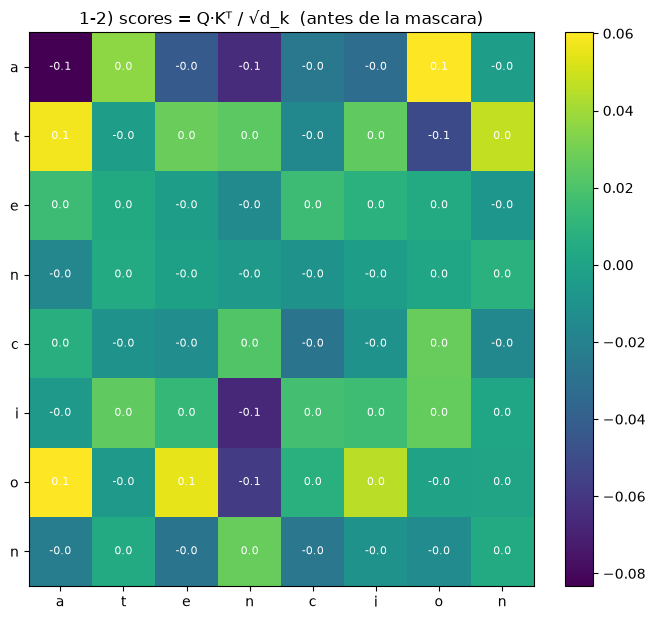

In [7]:
# Paso 1 y 2: puntuaciones escaladas
scores = (Q @ K.T) / np.sqrt(d_k)        # [T, T]
heatmap(scores, '1-2) scores = Q·Kᵀ / √d_k  (antes de la mascara)',
        xt=tok_labels, yt=tok_labels, fmt='.1f')

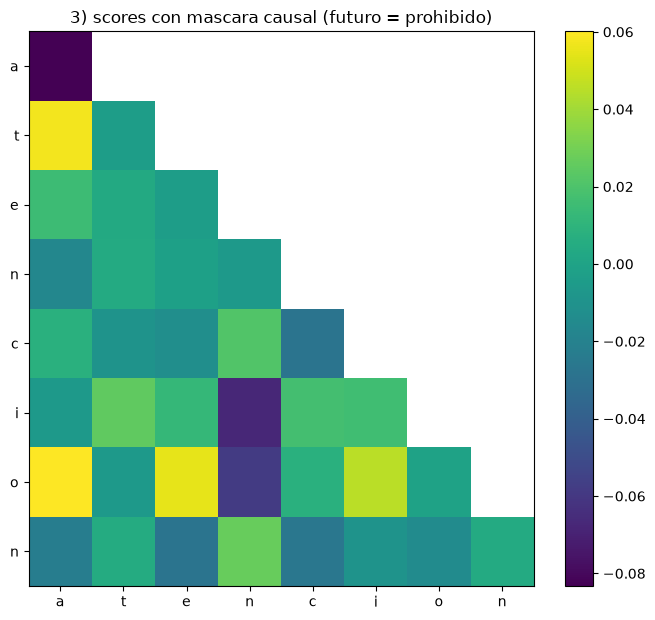

In [8]:
# Paso 3: mascara causal -> cada token solo ve el presente y el pasado
mask = np.triu(np.ones((T, T)), k=1).astype(bool)   # True = futuro (prohibido)
scores_masked = scores.copy()
scores_masked[mask] = -np.inf
heatmap(np.where(np.isinf(scores_masked), np.nan, scores_masked),
        '3) scores con mascara causal (futuro = prohibido)',
        xt=tok_labels, yt=tok_labels)

Suma de cada fila (debe ser 1): [1. 1. 1. 1. 1. 1. 1. 1.]


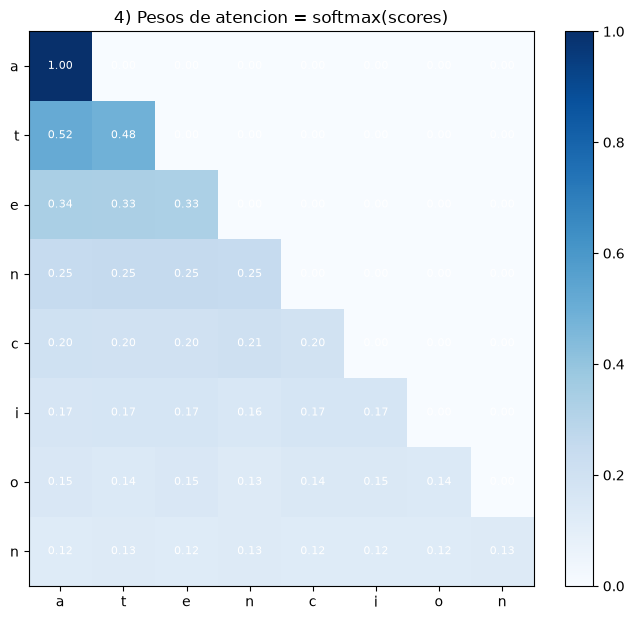

In [9]:
# Paso 4: softmax por fila -> pesos de atencion (cada fila suma 1)
attn = softmax(scores_masked, axis=-1)   # [T, T]
print('Suma de cada fila (debe ser 1):', np.round(attn.sum(1), 3))
heatmap(attn, '4) Pesos de atencion = softmax(scores)',
        xt=tok_labels, yt=tok_labels, cmap='Blues', fmt='.2f')

**Cómo leer el mapa anterior:** la fila *i* dice **cuánto** atiende el token *i* a cada token de
la secuencia. Fíjate en el **triángulo inferior**: por la máscara causal, el primer token solo se
atiende a sí mismo, y cada token siguiente reparte su atención entre él y los anteriores. **Nunca**
hacia el futuro.

In [10]:
# La salida de la atencion: combinacion ponderada de los valores V
salida = attn @ Vv               # [T, d_k]
print('Salida de la atencion (una fila por token):', salida.shape)
print('\nNueva representacion del token', tok_labels[-1], '(ultima fila):')
print(np.round(salida[-1], 3))

Salida de la atencion (una fila por token): (8, 16)

Nueva representacion del token n (ultima fila):
[ 0.036  0.014 -0.011 -0.125  0.026 -0.082  0.07   0.018  0.014 -0.021
 -0.026  0.012  0.072 -0.051  0.094 -0.015]


> 🛠️ **EJERCICIO 3.** Comenta la línea de la máscara causal (`scores_masked[mask] = -np.inf`) y
> vuelve a ejecutar. ¿Qué cambia en el mapa de atención? ¿Por qué un modelo que **predice el
> siguiente** token **no debe** ver el futuro durante el entrenamiento?

## 4 · Multi-Head Attention — varias miradas en paralelo

Una sola atención capta **un** tipo de relación. El Transformer usa **varias cabezas** en paralelo:
cada una aprende a fijarse en algo distinto (concordancia, sujeto-verbo, puntuación…). Luego se
**concatenan** y se proyectan de vuelta a dimensión `d`. Es el mismo cálculo de antes, repetido `h`
veces — **álgebra lineal masivamente paralela**.

Salida multi-cabeza: (8, 16)  (combina 4 cabezas)


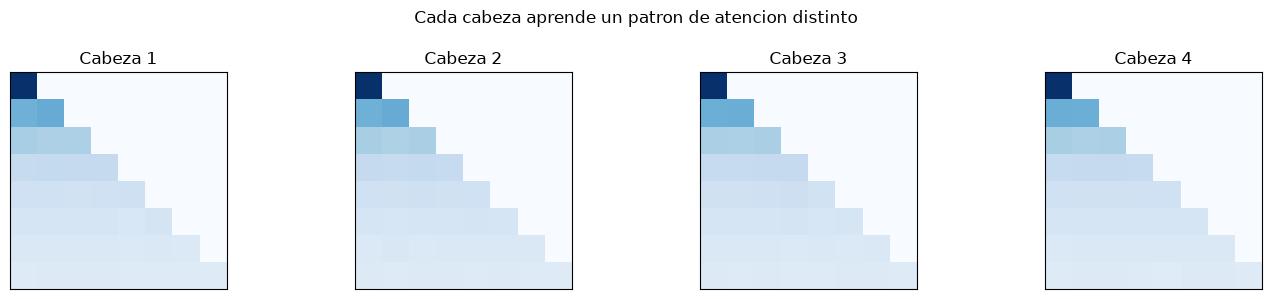

In [11]:
def attention(X, Wq, Wk, Wv, causal=True):
    Q, K, Vv = X @ Wq, X @ Wk, X @ Wv
    s = (Q @ K.T) / np.sqrt(Wk.shape[1])
    if causal:
        s[np.triu(np.ones_like(s), k=1).astype(bool)] = -np.inf
    a = softmax(s, axis=-1)
    return a @ Vv, a

def multi_head(X, h=4):
    dh = d // h                       # dimension por cabeza
    salidas, mapas = [], []
    for _ in range(h):
        wq = np.random.randn(d, dh) * 0.3
        wk = np.random.randn(d, dh) * 0.3
        wv = np.random.randn(d, dh) * 0.3
        o, a = attention(X, wq, wk, wv)
        salidas.append(o); mapas.append(a)
    concat = np.concatenate(salidas, axis=1)   # [T, d]
    Wo = np.random.randn(d, d) * 0.3
    return concat @ Wo, mapas

X = embed(encode('atencion'))
out, mapas = multi_head(X, h=4)
print(f'Salida multi-cabeza: {out.shape}  (combina {len(mapas)} cabezas)')

fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for k, (ax, a) in enumerate(zip(axes, mapas)):
    ax.imshow(a, cmap='Blues'); ax.set_title(f'Cabeza {k+1}')
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle('Cada cabeza aprende un patron de atencion distinto'); plt.tight_layout(); plt.show()

## 5 · El bloque Transformer completo

Un **bloque** Transformer apila la atención con una pequeña red **feed-forward (MLP)**, y añade dos
trucos que hacen entrenable a la red profunda:
- **Conexión residual** (`x + sublayer(x)`): deja "pasar" la información y facilita el flujo del gradiente.
- **LayerNorm**: normaliza cada vector para estabilizar el entrenamiento.

`x → LayerNorm → Atención → (+x) → LayerNorm → MLP → (+x)`

Apilar **N** de estos bloques es lo que da **profundidad** al modelo (GPT-3 tiene 96).

In [12]:
def layer_norm(x, eps=1e-5):
    mu = x.mean(-1, keepdims=True)
    var = x.var(-1, keepdims=True)
    return (x - mu) / np.sqrt(var + eps)

def mlp(x):
    W1 = np.random.randn(d, 4*d) * 0.1
    W2 = np.random.randn(4*d, d) * 0.1
    h = np.maximum(0, x @ W1)      # ReLU
    return h @ W2

def bloque_transformer(x):
    wq = np.random.randn(d, d)*0.3; wk = np.random.randn(d, d)*0.3; wv = np.random.randn(d, d)*0.3
    a, _ = attention(layer_norm(x), wq, wk, wv)
    x = x + a                       # residual 1
    x = x + mlp(layer_norm(x))      # residual 2
    return x

X = embed(encode('atencion'))
Y = bloque_transformer(X)
print('Entrada :', X.shape)
print('Salida  :', Y.shape, '  (misma forma -> se pueden APILAR bloques)')

Entrada : (8, 16)
Salida  : (8, 16)   (misma forma -> se pueden APILAR bloques)


## 6 · La cabeza de salida — predecir el **siguiente token**

Tras los bloques, una última capa lineal proyecta cada vector a `V` números: los **logits**, una
puntuación por cada token posible del vocabulario. Un **softmax** los convierte en una **distribución
de probabilidad** sobre "¿cuál es el siguiente carácter?".

Como **todavía no entrenamos nada** (pesos al azar), la predicción será **basura** — justo lo que
queremos demostrar: la arquitectura sola no sabe nada; el conocimiento vive en los **pesos aprendidos**.

In [13]:
W_head = np.random.randn(d, V) * 0.1
logits = Y @ W_head            # [T, V]
probs = softmax(logits[-1])    # distribucion para el SIGUIENTE token tras 'atencion'

top = np.argsort(probs)[::-1][:8]
print('Top-8 candidatos a siguiente caracter (modelo SIN entrenar):')
for i in top:
    print(f'   {itos[i]!r:>5}  prob = {probs[i]:.3f}')
print('\n(Probabilidades casi uniformes => el modelo aun no sabe nada.)')

Top-8 candidatos a siguiente caracter (modelo SIN entrenar):
     'S'  prob = 0.020
     ' '  prob = 0.019
     'N'  prob = 0.018
    '\n'  prob = 0.018
     'j'  prob = 0.018
     'q'  prob = 0.018
     't'  prob = 0.017
     'W'  prob = 0.017

(Probabilidades casi uniformes => el modelo aun no sabe nada.)


**Muestreo.** Una vez tenemos la distribución, elegimos el siguiente token. La **temperatura**
controla el azar: baja = conservador (elige lo más probable), alta = creativo (más aleatorio).

In [14]:
def muestrear(probs, temperatura=1.0, rng=np.random):
    logits = np.log(probs + 1e-9) / temperatura
    p = softmax(logits)
    return rng.choice(len(p), p=p)

rng = np.random.default_rng(0)
for t in [0.5, 1.0, 1.5]:
    elec = [itos[muestrear(probs, t, rng)] for _ in range(12)]
    print(f'temperatura={t}:  {elec}')

temperatura=0.5:  ['f', 'A', ' ', '\n', 'r', 'z', 'c', 'm', 'V', 'á', 'r', '\n']
temperatura=1.0:  ['v', ' ', 'm', '5', 'w', 'W', 'D', 'N', ' ', '1', 'h', 'f']
temperatura=1.5:  ['d', 'J', 'ú', 'ó', 'j', 'g', 'j', 'L', '2', 'l', 'V', 'E']


## 7 · Aprendizaje — **descenso por gradiente**

Hasta aquí todo fue *forward* con pesos al azar. Ahora viene **cómo aprende** un LLM. Ensamblamos las
**mismas piezas** (embeddings, atención, bloques, cabeza) en **PyTorch**, que calcula los gradientes
automáticamente, y entrenamos con el ciclo fundamental del *deep learning*:

```
para cada paso:
   1. forward : el modelo predice el siguiente token
   2. perdida : cross-entropy  (¿qué tan equivocado estuvo?)
   3. backward: gradientes     (¿cómo ajustar cada peso para fallar menos?)
   4. step    : el optimizador mueve los pesos un poquito (descenso por gradiente)
```

Repetido miles de veces, esto es **todo** el "aprendizaje" de un LLM.

In [15]:
import torch, torch.nn as nn, torch.nn.functional as F, time
torch.manual_seed(1337)

block = 32     # longitud de contexto
n_emb = 128     # dimension del modelo
n_head = 4     # cabezas de atencion
n_layer = 4    # bloques transformer apilados

data = torch.tensor(encode(texto), dtype=torch.long)
def get_batch(bs=32):
    ix = torch.randint(len(data) - block, (bs,))
    x = torch.stack([data[i:i+block]   for i in ix])
    y = torch.stack([data[i+1:i+block+1] for i in ix])
    return x, y
print('Datos de entrenamiento:', data.shape[0], 'tokens')

Datos de entrenamiento: 69004 tokens


In [16]:
class Cabeza(nn.Module):
    def __init__(self, hs):
        super().__init__()
        self.key   = nn.Linear(n_emb, hs, bias=False)
        self.query = nn.Linear(n_emb, hs, bias=False)
        self.value = nn.Linear(n_emb, hs, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(block, block)))
        self.hs = hs
    def forward(self, x):
        B, T, C = x.shape
        k, q = self.key(x), self.query(x)
        att = (q @ k.transpose(-2,-1)) * self.hs**-0.5      # scores escalados
        att = att.masked_fill(self.tril[:T,:T]==0, float('-inf'))  # mascara causal
        att = F.softmax(att, dim=-1)
        return att @ self.value(x)

class MultiCabeza(nn.Module):
    def __init__(self):
        super().__init__()
        self.heads = nn.ModuleList([Cabeza(n_emb//n_head) for _ in range(n_head)])
        self.proj  = nn.Linear(n_emb, n_emb)
    def forward(self, x):
        return self.proj(torch.cat([h(x) for h in self.heads], dim=-1))

class Bloque(nn.Module):
    def __init__(self):
        super().__init__()
        self.sa = MultiCabeza()
        self.ff = nn.Sequential(nn.Linear(n_emb,4*n_emb), nn.ReLU(), nn.Linear(4*n_emb,n_emb))
        self.ln1, self.ln2 = nn.LayerNorm(n_emb), nn.LayerNorm(n_emb)
    def forward(self, x):
        x = x + self.sa(self.ln1(x))   # atencion + residual
        x = x + self.ff(self.ln2(x))   # mlp + residual
        return x

class MiniGPT(nn.Module):
    def __init__(self):
        super().__init__()
        self.tok = nn.Embedding(V, n_emb)
        self.pos = nn.Embedding(block, n_emb)
        self.blocks = nn.Sequential(*[Bloque() for _ in range(n_layer)])
        self.lnf  = nn.LayerNorm(n_emb)
        self.head = nn.Linear(n_emb, V)
    def forward(self, idx, targets=None):
        B, T = idx.shape
        x = self.tok(idx) + self.pos(torch.arange(T))
        x = self.lnf(self.blocks(x))
        logits = self.head(x)
        loss = None if targets is None else \
               F.cross_entropy(logits.view(-1, V), targets.view(-1))
        return logits, loss
    @torch.no_grad()
    def generar(self, idx, n, temp=1.0):
        for _ in range(n):
            logits, _ = self(idx[:, -block:])
            probs = F.softmax(logits[:, -1, :] / temp, dim=-1)
            idx = torch.cat([idx, torch.multinomial(probs, 1)], dim=1)
        return idx

modelo = MiniGPT()
n_par = sum(p.numel() for p in modelo.parameters())
print(f'Mini-GPT creado con {n_par:,} parametros entrenables')

Mini-GPT creado con 815,436 parametros entrenables


**Generación ANTES de entrenar.** Le damos un token inicial y dejamos que escriba. Con los pesos
al azar, debería salir un galimatías.

In [17]:
ctx = torch.zeros((1,1), dtype=torch.long)
print('ANTES de entrenar:')
print(repr(decode(modelo.generar(ctx, 120)[0].tolist())))

ANTES de entrenar:
'\nézklá+;.jwWvuóSDWtFgaé+Qz3RvFTjtvJEJEP50skXR;ímhyVeTE/CcWj/xóóaG6wH;;2CGa;L0;íó9Gav6tSd79T.sééo4gc4íSB:Lñ.Z p; sctwg55 m'


In [18]:
# ===== CICLO DE ENTRENAMIENTO (descenso por gradiente) =====
optimizador = torch.optim.AdamW(modelo.parameters(), lr=3e-3)
PASOS = 1500
historia = []
t0 = time.time()
for paso in range(PASOS):
    xb, yb = get_batch()                 # 1) datos
    _, perdida = modelo(xb, yb)          #    forward + perdida
    optimizador.zero_grad(set_to_none=True)
    perdida.backward()                   # 3) backward -> gradientes
    optimizador.step()                   # 4) step    -> ajusta pesos
    if paso % 100 == 0 or paso == PASOS-1:
        historia.append((paso, perdida.item()))
        print(f'paso {paso:4d} | perdida = {perdida.item():.3f}')
print(f'\nEntrenado en {time.time()-t0:.1f} s')

paso    0 | perdida = 4.495
paso  100 | perdida = 2.053
paso  200 | perdida = 1.626
paso  300 | perdida = 1.381
paso  400 | perdida = 1.239
paso  500 | perdida = 1.189
paso  600 | perdida = 1.180
paso  700 | perdida = 1.145
paso  800 | perdida = 1.007
paso  900 | perdida = 0.898
paso 1000 | perdida = 0.857
paso 1100 | perdida = 0.864
paso 1200 | perdida = 0.784
paso 1300 | perdida = 0.761
paso 1400 | perdida = 0.707
paso 1499 | perdida = 0.701

Entrenado en 235.4 s


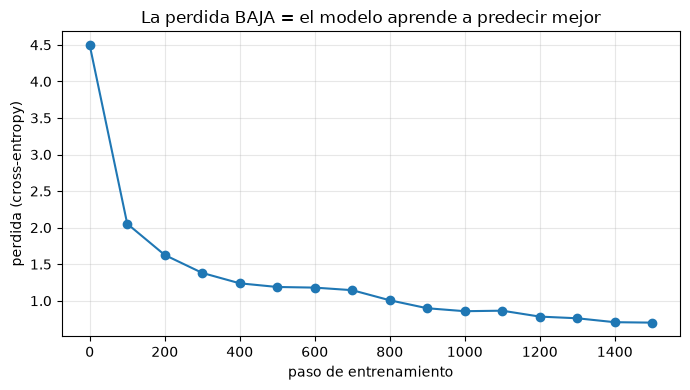

In [19]:
ps, ls = zip(*historia)
plt.figure(figsize=(7,4))
plt.plot(ps, ls, marker='o')
plt.xlabel('paso de entrenamiento'); plt.ylabel('perdida (cross-entropy)')
plt.title('La perdida BAJA = el modelo aprende a predecir mejor')
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

**Generación DESPUÉS de entrenar.** Los mismos pesos, ahora ajustados por el descenso por
gradiente. El modelo debería producir **español coherente** parecido al corpus — sin que nadie le
diera reglas de gramática: las **dedujo** de los datos.

In [30]:
print('DESPUES de entrenar:')
print(repr(decode(modelo.generar(ctx, 240, temp=0.8)[0].tolist())))

DESPUES de entrenar:
'\nada que escritorio, el sistema solo chip, SPC, capacidad las a los distribuidos que en un sistema de tiempo real, no tiene esta se sistema operativo de tiempo real y otro se permite todo la comóencil, tentran los microcontroladores de propó'


In [32]:
ctx = torch.zeros((1,1), dtype=torch.long)

print('Temperatura baja ((0.3):')
print(repr(decode(modelo.generar(ctx, 240, temp=0.3)[0].tolist())))
print('Temperatura baja ((0.8):')
print(repr(decode(modelo.generar(ctx, 240, temp=0.3)[0].tolist())))


Temperatura baja ((0.3):
'\nEn su plazo. Usuario se se no cutada de ser una salida de señal PWM para formar de los sistemas embebidos se encarga de grante fallar para ser confiable y eficaencias a la interrupción de energía de procesador simple, el destritario de la a'
Temperatura baja ((0.8):
'\nEn el planificador de programas y reloj estan en tipo dos de milisegmentos, sino que sistemas embebidos se estrictos que se utilizan los recursos tiene el mismo de sistemas operativos embebidos se estricas que segundos el sistema de tiempo '


> 🛠️ **EJERCICIO 7.** Vuelve a la celda de hiperparámetros y prueba `PASOS = 300`. ¿El texto es
> peor? Ahora sube `n_layer` o `n_emb`. ¿Mejora? Relaciona lo que observas con la palabra **escala**.

## 8 · Escala y capacidades emergentes

Acabas de construir un LLM **completo y funcional**. Su arquitectura es, *literalmente*, la misma que
la de los modelos de frontera. La única diferencia es la **escala**.

In [26]:
print(f'{"Modelo":<22}{"Parametros":>16}{"~Capas":>9}{"~d_model":>10}')
print('-'*57)
filas = [
    ('Nuestro Mini-GPT', f'{n_par:,}', n_layer, n_emb),
    ('GPT-2 small',      '124,000,000',   12,   768),
    ('GPT-3',            '175,000,000,000',96, 12288),
    ('GPT-4 (estimado)', '~1.7 billones',  '~120', '~18k'),
]
for nombre, par, capas, dm in filas:
    print(f'{nombre:<22}{par:>16}{str(capas):>9}{str(dm):>10}')

ratio = 175_000_000_000 / n_par
print(f'\nGPT-3 tiene ~{ratio:,.0f} veces mas parametros que tu modelo,')
print('pero CADA operacion interna es la misma que implementaste aqui.')

Modelo                      Parametros   ~Capas  ~d_model
---------------------------------------------------------
Nuestro Mini-GPT               815,436        4       128
GPT-2 small                124,000,000       12       768
GPT-3                  175,000,000,000       96     12288
GPT-4 (estimado)         ~1.7 billones     ~120      ~18k

GPT-3 tiene ~214,609 veces mas parametros que tu modelo,
pero CADA operacion interna es la misma que implementaste aqui.


### ¿Por qué "emergen" capacidades?
Tu modelo aprendió **ortografía y estructura** del español a partir de puro texto. Al multiplicar la
escala por millones —más parámetros, más datos, más cómputo— aparecen **habilidades que no estaban
programadas** y que **no surgen** en redes pequeñas: traducir, razonar paso a paso, escribir código,
seguir instrucciones. A esto se le llama **capacidades emergentes**.

La lección de este laboratorio: **no hay un componente mágico**. Hay tokenización, embeddings,
atención, MLPs, residuales y un softmax — todo es **álgebra lineal masivamente paralela**— y un
**descenso por gradiente** que ajusta millones de números hasta que el modelo predice bien el
siguiente token. La inteligencia aparente **emerge de la escala** de algo muy simple repetido
muchísimas veces.

##  Para llevar (resumen de una página)

| Paso | Pieza | Qué hace | Operación clave |
|---|---|---|---|
| 1 | **Tokenización** | texto → enteros | tabla de búsqueda |
| 2 | **Embeddings** | enteros → vectores (+ posición) | búsqueda en `E` + suma |
| 3 | **Self-Attention** | cada token mira a los demás | `softmax(QKᵀ/√d)·V` |
| 4 | **Multi-Head** | varias relaciones en paralelo | concatenar cabezas |
| 5 | **Bloque** | profundidad estable | residual + LayerNorm + MLP |
| 6 | **Cabeza** | predecir siguiente token | proyección + `softmax` |
| 7 | **Entrenamiento** | aprender de los datos | cross-entropy + **descenso por gradiente** |
| 8 | **Escala** | capacidades emergentes | lo mismo × millones |

---



###  Preguntas
1. ¿Por qué un LLM necesita convertir el texto en números antes de procesarlo?
2. ¿Qué representa una **fila** de la matriz de atención? ¿Por qué usamos **máscara causal**?
3. En el ciclo de entrenamiento, ¿qué papel cumple la **pérdida** y qué hace el **descenso por gradiente**?
4. Con la **misma arquitectura**, ¿por qué GPT-3 puede hacer cosas que tu Mini-GPT no? Define
   **capacidad emergente** con tus palabras.
5. ¿En qué sentido es cierto que un LLM "es álgebra lineal masivamente paralela"?

###  Actividades
- Cambia el `texto` por uno tuyo (apuntes de clase, un poema) y reentrena. ¿Aprende su estilo?
- Implementa **top-k sampling** en `generar(...)` y compáralo con la temperatura.
- Grafica la **matriz de atención del modelo ya entrenado** y compárala con la del modelo sin entrenar.

---
###  Para profundizar
- *Attention Is All You Need* (Vaswani et al., 2017) — el paper original del Transformer.
- A. Karpathy, *Let's build GPT from scratch* — construcción de un GPT en video.

*Fin del laboratorio.* 🧠